In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

from sklearn.dummy import DummyClassifier

In [28]:
X=df.drop("fraud",axis=1)
y=df["fraud"]

In [31]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [32]:
numeric_features = [
    "islem_tutari",
    "hesap_yasi_gun",
    "son_24s_islem_sayisi",
    "ortalama_islem_tutari",
    "ip_risk_skoru",
    "islem_saati",
    "basarisiz_giris_sayisi"
]

categorical_features = [
    "cihaz_degisti",
    "ulke_farkli",
    "kart_tipi",
    "teslimat_adresi_farkli"
]

In [33]:
numeric_transform = Pipeline(
    steps=[
    ("imputer",SimpleImputer(strategy="median"))
    ]
)

In [34]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

In [35]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",numeric_transform,numeric_features),
        ("cat",categorical_transformer,categorical_features)
    ]
)

In [36]:
gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=2,
                subsample=0.8,
                random_state=42
            )
        )
    ]
)

In [37]:
gb_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
y_pred = gb_model.predict(X_test)

In [39]:
y_proba = gb_model.predict_proba(X_test)[:,1]

In [40]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.93      1.00      0.96       371
           1       0.00      0.00      0.00        29

    accuracy                           0.93       400
   macro avg       0.46      0.50      0.48       400
weighted avg       0.86      0.93      0.89       400



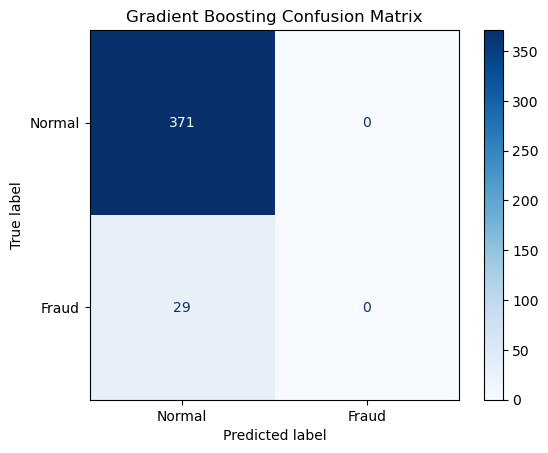

In [41]:
cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

disp.plot(cmap="Blues")

plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [42]:
roc_auc = roc_auc_score(
    y_test,
    y_proba
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.609071475044149


In [43]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_pred = dummy_model.predict(
    X_test
)

print(
    classification_report(
        y_test,
        dummy_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.93      1.00      0.96       371
           1       0.00      0.00      0.00        29

    accuracy                           0.93       400
   macro avg       0.46      0.50      0.48       400
weighted avg       0.86      0.93      0.89       400



In [44]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=6,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [45]:
rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_proba = rf_model.predict_proba(
    X_test
)[:, 1]

In [46]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting"
    ],
    "Precision": [
        precision_score(y_test, rf_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_proba),
        roc_auc_score(y_test, y_proba)
    ]
})

print(results)

               Model  Precision  Recall   F1   ROC-AUC
0      Random Forest        0.0     0.0  0.0  0.568083
1  Gradient Boosting        0.0     0.0  0.0  0.609071
